# Lab: Data Visualization and Visual Thinking

The U.S. Bureau of Transportation Statistics collects information about scheduled domestic flights. In this lab, you will use the ideas from **Data Visualization and Visual Thinking** to examine a documented sample of 5,000 completed, non-diverted flights from May 2026.


## Learning goals

By the end of this lab, you should be able to:

- load and inspect a CSV file as a Pandas DataFrame;
- distinguish Pandas data types from quantitative and categorical feature types;
- check for missing values;
- create and label a histogram and a bar chart;
- describe a distribution by its typical values, range, and skew;
- use `.describe()` to check estimates made from a histogram;
- explain how histogram bins and axis scales affect a figure; and
- identify conclusions that can and cannot be supported by a sample; and
- find a documented dataset, audit every feature, and interpret its quantitative and categorical distributions.


## Using AI tools responsibly

You may use an AI tool to ask questions, debug code, or receive feedback. You are still responsible for understanding every part of your submission and checking suggestions against your notebook's output. At the end of the lab, disclose whether you used an AI tool and how you evaluated its advice.


## Dataset

The [U.S. Bureau of Transportation Statistics (BTS) Reporting Carrier On-Time Performance data](https://www.transtats.bts.gov/DL_SelectFields.aspx?QO_fu146_anzr=b0-gvzr&gnoyr_VQ=FGJ) contains 611,735 reported domestic flight records for May 2026. Completed, non-diverted flights with recorded values for all five selected features were eligible for this lab. Canceled flights, diverted flights, and records missing any selected feature were excluded before the sample was drawn.

The dataset is a reproducible random sample of 5,000 eligible flights. Each observation represents one completed, non-diverted domestic flight in that sample. Because incomplete records were removed before sampling, finding no missing values in the dataset does not mean that the original BTS data had no missing values. Conclusions from this sample describe the eligible flights and should not automatically be generalized to canceled or diverted flights.

| Feature | Description |
| --- | --- |
| `airline` | Airline that reported the flight |
| `origin_city` | Departure city |
| `destination_city` | Arrival city |
| `distance_miles` | Nonstop flight distance in miles |
| `arrival_delay_minutes` | Minutes between scheduled and actual arrival; negative values mean the flight arrived early |


## Load and preview the data

Import Pandas using the conventional alias `pd`. Read `data/bts_flights_may_2026_sample.csv` into a DataFrame named `flights`.


In [1]:
# Write your code here.
import pandas as pd
flights = pd.read_csv("data/bts_flights_may_2026_sample.csv")

Display the first five rows of the DataFrame.


In [2]:
# Write your code here.
flights.head()

,airline,origin_city,destination_city,distance_miles,arrival_delay_minutes
0,Alaska Airlines,"Anchorage, AK","Chicago, IL",2846,65
1,Alaska Airlines,"Anchorage, AK","Cordova, AK",160,-1
2,Alaska Airlines,"Anchorage, AK","Fairbanks, AK",261,-18
3,Alaska Airlines,"Anchorage, AK","Juneau, AK",571,-21
4,Alaska Airlines,"Anchorage, AK","Juneau, AK",571,-14


Display the last five rows of the DataFrame.


In [3]:
# Write your code here.
flights.tail()

,airline,origin_city,destination_city,distance_miles,arrival_delay_minutes
4995,United Airlines,"West Palm Beach/Palm Beach, FL","Chicago, IL",1144,0
4996,United Airlines,"West Palm Beach/Palm Beach, FL","Houston, TX",956,-22
4997,United Airlines,"West Palm Beach/Palm Beach, FL","Houston, TX",956,-29
4998,United Airlines,"West Palm Beach/Palm Beach, FL","Newark, NJ",1024,-26
4999,United Airlines,"West Palm Beach/Palm Beach, FL","Newark, NJ",1024,7


## Inspect the DataFrame

Display a summary of the DataFrame that includes the feature names, the number of non-missing values, and the Pandas data types.


In [4]:
# Write your code here.
flights.info()

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 5 columns):
 #   Column                 Non-Null Count  Dtype
---  ------                 --------------  -----
 0   airline                5000 non-null   str  
 1   origin_city            5000 non-null   str  
 2   destination_city       5000 non-null   str  
 3   distance_miles         5000 non-null   int64
 4   arrival_delay_minutes  5000 non-null   int64
dtypes: int64(2), str(3)
memory usage: 399.5 KB


**How many observations are in the DataFrame?**

Your answer: 5000


Count the missing values in every feature.


In [5]:
# Write your code here.
flights.isnull().sum()

airline                  0
origin_city              0
destination_city         0
distance_miles           0
arrival_delay_minutes    0
dtype: int64

## Classify the features

A **quantitative feature** records an amount or measurement for which arithmetic is meaningful. A **categorical feature** assigns observations to groups or labels.


**Complete the table with the Pandas data type, feature type, and number of missing values for each feature. Use `.info()` and `.isnull().sum()`; enter 0 when no values are missing.**

| Feature | Pandas data type | Feature type | Number of missing values |
| --- | --- | --- | ---: |
| `airline` | str | categorical | 0 |
| `origin_city` | str | categorical | 0 |
| `destination_city` | str | categorical | 0 |
| `distance_miles` | int64 | quantitative | 0 |
| `arrival_delay_minutes` | int64 | quantitative | 0 |


## Which destination city is most common in the sample?

Calculate and display the frequency of each destination city. Save the result as `destination_counts`.


In [6]:
# Write your code here.
destination_counts = flights["destination_city"].value_counts()
destination_counts

destination_city
Chicago, IL                      296
Atlanta, GA                      222
Dallas/Fort Worth, TX            210
Denver, CO                       209
Washington, DC                   165
                                ... 
Watertown, SD                      1
Cedar City, UT                     1
Sun Valley/Hailey/Ketchum, ID      1
Carlsbad, CA                       1
Redding, CA                        1
Name: count, Length: 238, dtype: int64

Import `matplotlib.pyplot` using the conventional alias `plt`. Use `.head(10)` on `destination_counts` to select the ten most frequent destination cities, then create a bar chart. Give the figure a descriptive title and label both axes.


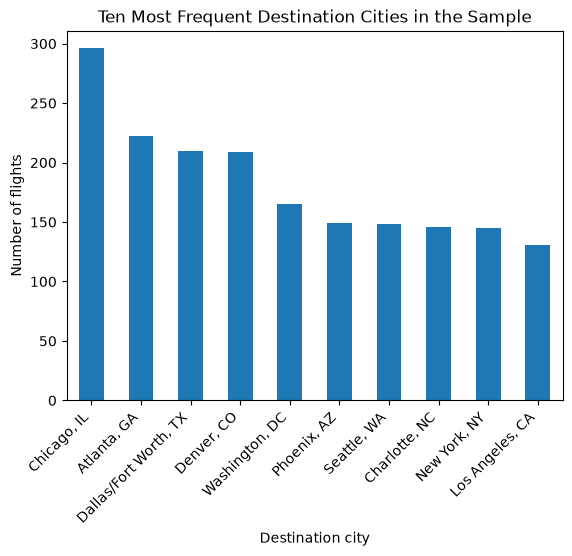

In [7]:
# Write your code here.
import matplotlib.pyplot as plt
top_destinations = destination_counts.head(10)
top_destinations.plot(kind="bar")
plt.title("Ten Most Frequent Destination Cities in the Sample")
plt.xlabel("Destination city")
plt.ylabel("Number of flights")
plt.xticks(rotation=45, ha="right")
plt.show()

**Which destination city is most common in the sample?**

Your answer: Chicago, IL


## What was the distribution of arrival delays?

Negative values represent early arrivals, zero represents an on-time arrival, and positive values represent late arrivals.

Create a histogram of `arrival_delay_minutes` using the default number of bins. Give the figure a descriptive title and label both axes.


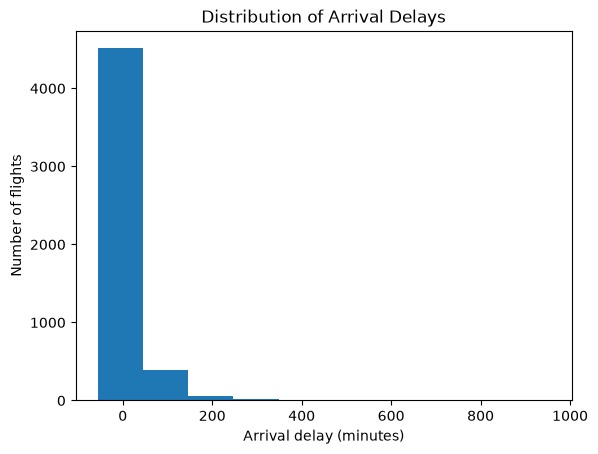

In [8]:
# Write your code here.
flights["arrival_delay_minutes"].plot(kind="hist")
plt.title("Distribution of Arrival Delays")
plt.xlabel("Arrival delay (minutes)")
plt.ylabel("Number of flights")
plt.show()

**Approximately what arrival-delay value appears most common?**

Your answer: 0


**What is the approximate range from the smallest to the largest arrival-delay value?**

Your answer: 0-350


**Does the arrival-delay distribution appear symmetric or skewed?**

Your answer: Right skewed.


Display a numerical summary of `arrival_delay_minutes`.


In [9]:
# Write your code here.
flights["arrival_delay_minutes"].describe()

count    5000.000000
mean        6.098800
std        48.335493
min       -55.000000
25%       -16.000000
50%        -6.000000
75%        10.000000
max       953.000000
Name: arrival_delay_minutes, dtype: float64

Calculate and display the exact mode of `arrival_delay_minutes` using `.mode()`.


In [10]:
# Write your code here.
flights["arrival_delay_minutes"].mode()

0   -8
Name: arrival_delay_minutes, dtype: int64

**How closely did the calculated mode match the most common value you estimated from the histogram?**

Your answer: The first bin contained -8 so not too far off from 0, but it's hard to tell from the histogram. 


**How closely did the minimum and maximum from `.describe()` match the range you estimated from the histogram?**

Your answer: Minimum was close but maximum was way off. I can't see any bins on the right side. It makes sense why that axis exteds to 1000 now though.


**Is the mean greater than, less than, or approximately equal to the median?**

Your answer: The mean (6.10) is greater than the median (-6.0).


**How is the relationship between the mean and median connected to the histogram's shape?**

Your answer: The long right tail pulls the mean upward, while the median stays near the typical value. Most flights arrived early/on time, but a relatively small number of very late flights raise the mean.


## Applying the principles: histogram bins

Re-create the arrival-delay histogram using exactly 5 bins.


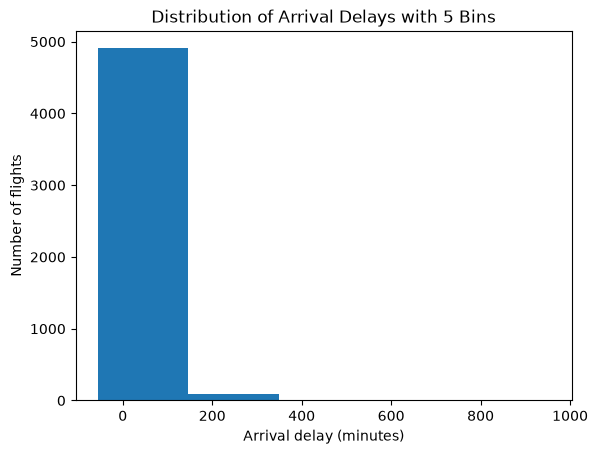

In [11]:
# Write your code here.
flights["arrival_delay_minutes"].plot(kind="hist", bins=5)
plt.title("Distribution of Arrival Delays with 5 Bins")
plt.xlabel("Arrival delay (minutes)")
plt.ylabel("Number of flights")
plt.show()

Re-create the arrival-delay histogram using exactly 25 bins.


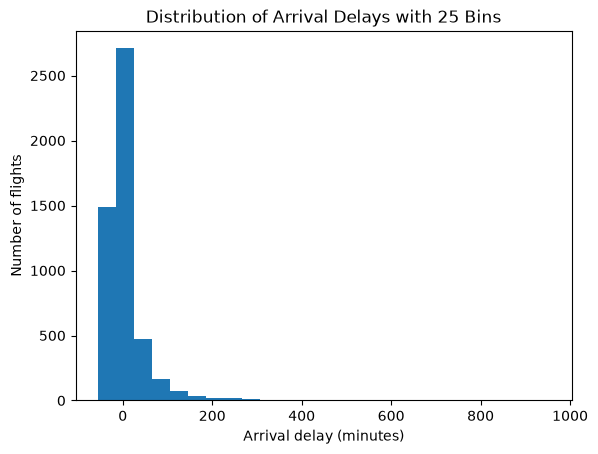

In [12]:
# Write your code here.
flights["arrival_delay_minutes"].plot(kind="hist", bins=25)
plt.title("Distribution of Arrival Delays with 25 Bins")
plt.xlabel("Arrival delay (minutes)")
plt.ylabel("Number of flights")
plt.show()

**What changed when the number of bins was reduced to 5?**

Your answer: A lot of details get lost.


**What changed when the number of bins was increased to 25?**

Your answer: More details, a little easier to tell some arrivals were early. Still difficult to see the tail or anything past ~350.


**Which bin setting communicates the distribution most clearly?**

Your answer: I think the 25 is a little clearer.


## Applying the principles: a misleading vertical axis

Run both cells below and compare the figures.


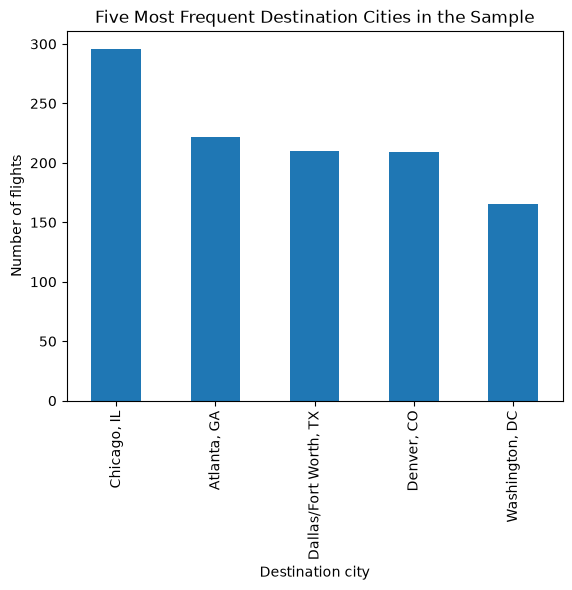

In [13]:
top_destinations = destination_counts.head(5)
top_destinations.plot(kind="bar")
plt.title("Five Most Frequent Destination Cities in the Sample")
plt.xlabel("Destination city")
plt.ylabel("Number of flights")
plt.show()


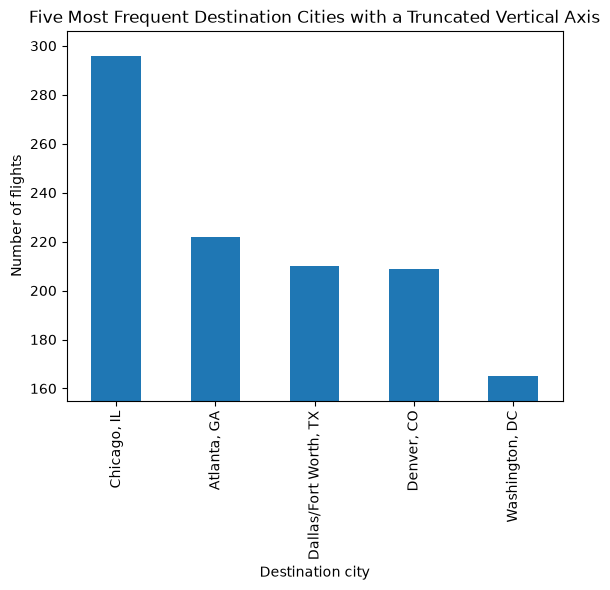

In [14]:
top_destinations.plot(kind="bar")
plt.ylim(top_destinations.min() - 10, top_destinations.max() + 10)
plt.title("Five Most Frequent Destination Cities with a Truncated Vertical Axis")
plt.xlabel("Destination city")
plt.ylabel("Number of flights")
plt.show()


**How does the truncated axis change the apparent differences among the destination cities?**

Your answer: The truncated axis makes it look like Chicago was more than double the next closest city and over 10 times the lowest one.


**Which chart communicates the counts more honestly?**

Your answer: The chart that starts at 0 shows a more honest comparison.


## Is this sample representative?

Review the dataset description at the top of the lab before answering these questions.


**What time period is represented by the source data?**

Your answer: May 2026


**Which flights were eligible to be included in the sample?**

Your answer:  Completed, non-diverted domestic flights with recorded values for all five selected features.


**Which flights and records were excluded before the sample was selected?**

Your answer: Canceled flights, diverted flights, and records missing any selected feature.


**Does finding no missing values in the sample prove that the original BTS data had no missing values?**

Your answer: It does not prove the original BTS data had no missing values, incomplete records were removed before the sample was drawn.


**Why should conclusions from this sample not automatically be generalized to canceled or diverted flights?**

Your answer: It should not automatically be generalized because they were deliberately excluded and may differ from completed flights (for example, in delays and disruption).


## Choosing a chart

Choose a histogram, bar chart, or pie chart for each question. Use the question and number of categories to justify your choice.


**Which chart would you use to show the frequency of each airline?**

Your answer: Airline has 13 different airlines so I think a bar chart would be the best way to compare them.


**Which chart would you use to show what proportion of sampled flights were early, on time, and delayed? Use arrival delays below 0, equal to 0, and above 0 minutes, respectively.**

Your answer: With only 3 categories to show, a pie chart would be easy to read.


**Which chart would you use to show the distribution of flight distances?**

Your answer: Flight distance is a quantitative feature with many distinct values rather than a small fixed set of categories, so a histogram would be the best option for showing its distribution.


## Explore a dataset of your own

Apply the same inspection and visualization process to a different dataset that interests you.

### 1. Find and describe your dataset

Start with [Kaggle Datasets](https://www.kaggle.com/datasets), the [UCI Machine Learning Repository](https://archive.ics.uci.edu/), or [Data.gov](https://catalog.data.gov/). You can also search a city or state open-data portal. Search for a topic you enjoy, such as sports, music, animals, transportation, or the environment.

Choose a manageable CSV file with a data dictionary (or equivalent feature documentation), at least one quantitative feature, and at least one categorical feature with a manageable number of categories. Use a different dataset from the flights and penguins already used in class. Save the file in this notebook's `data` folder.

Read the data dictionary before choosing your features. In a short paragraph, describe the dataset's subject, what one row represents, and its time period and geographic coverage if documented. Include its title, publisher or creator, a direct link to the dataset, and a link to the data dictionary. State when information is not documented instead of guessing.


**Dataset description and source links:**

Your answer: Extrovert vs. Introvert Behavior Data is a Kaggle dataset published by Rakesh Kapilavayi under CC BY-SA 4.0. It contains 2,900 rows and 8 columns describing social behaviors and personality: daily time spent alone, stage fear, social-event attendance, going outside, feeling drained after socializing, close-friend count, social-media posting frequency, and an Extrovert/Introvert label. Each row represents one person’s record of those behaviors and personality label. The documentation does not state the collection period, geographic coverage, or sampling method, so I will not generalize beyond these records.

Dataset: https://www.kaggle.com/datasets/rakeshkapilavai/extrovert-vs-introvert-behavior-data  
Data dictionary/feature list: https://www.kaggle.com/datasets/rakeshkapilavai/extrovert-vs-introvert-behavior-data/data


### 2. Load the data and describe every feature

Load your CSV into a new DataFrame with a descriptive name ending in `_df`, such as `movies_df`, `weather_df`, or `animals_df`. Choose a name that describes your dataset and use it consistently throughout your analysis. Display its first five rows, shape, `.info()`, and `.isnull().sum()` to inspect its features, storage types, and missing values. Use a relative path so your notebook can run on another computer.


In [15]:
# Load and inspect your chosen dataset here.
personality_df = pd.read_csv("data/personality_dataset.csv")

personality_df.head()

,Time_spent_Alone,Stage_fear,Social_event_attendance,Going_outside,Drained_after_socializing,Friends_circle_size,Post_frequency,Personality
0,4.0,No,4.0,6.0,No,13.0,5.0,Extrovert
1,9.0,Yes,0.0,0.0,Yes,0.0,3.0,Introvert
2,9.0,Yes,1.0,2.0,Yes,5.0,2.0,Introvert
3,0.0,No,6.0,7.0,No,14.0,8.0,Extrovert
4,3.0,No,9.0,4.0,No,8.0,5.0,Extrovert


In [16]:
personality_df.shape

(2900, 8)

In [17]:
personality_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2900 entries, 0 to 2899
Data columns (total 8 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Time_spent_Alone           2837 non-null   float64
 1   Stage_fear                 2827 non-null   str    
 2   Social_event_attendance    2838 non-null   float64
 3   Going_outside              2834 non-null   float64
 4   Drained_after_socializing  2848 non-null   str    
 5   Friends_circle_size        2823 non-null   float64
 6   Post_frequency             2835 non-null   float64
 7   Personality                2900 non-null   str    
dtypes: float64(5), str(3)
memory usage: 221.4 KB


In [18]:
personality_df.isnull().sum()

Time_spent_Alone             63
Stage_fear                   73
Social_event_attendance      62
Going_outside                66
Drained_after_socializing    52
Friends_circle_size          77
Post_frequency               65
Personality                   0
dtype: int64

Complete the table below with **one row for every feature** in your dataset. Add as many rows as needed. Use the data dictionary to summarize what each feature means, including units or category-code meanings where relevant.

- **Data type:** quantitative or categorical; identify identifiers and date/time features explicitly when appropriate. A numeric identifier is not a quantitative measurement.
- **Data storage type:** the actual Pandas dtype shown by `.info()` or `.dtypes`, such as `int64`, `float64`, `object`, `str`, or `datetime64[ns]`.
- **Missing values:** the number reported for that feature, including 0 when there are none. Count missing values before removing records. If the dictionary defines special missing codes, such as -999 or "Unknown", explain how you handle those codes and make sure the counts reflect that decision.


| Feature | Description from the data dictionary (including units/codes) | Data type | Data storage type | Number of missing values |
| --- | --- | --- | --- | ---: |
| Time_spent_Alone | Hours spent alone daily (0–11) | quantitative | float64 | 63 |
| Stage_fear | Presence of stage fright (Yes/No) | categorical | str | 73 |
| Social_event_attendance | Frequency of social events (0–10) | quantitative | float64 | 62 |
| Going_outside | Frequency of going outside (0–7) | quantitative | float64 | 66 |
| Drained_after_socializing | Feeling drained after socializing (Yes/No) | categorical | str | 52 |
| Friends_circle_size | Number of close friends (0–15) | quantitative | float64 | 77 |
| Post_frequency | Social media post frequency (0–10) | quantitative | float64 | 65 |
| Personality | Target variable (Extrovert/Introvert) | categorical | str | 0 |

**Missing-value codes or other data preparation, if applicable:**

Your answer: The documentation defines no special missing codes. Blank cells are read as missing (NaN).


### 3. Visualize one quantitative feature

Choose one quantitative measurement and create an appropriate visualization of its distribution, such as a histogram. Include a descriptive title, a horizontal-axis label naming the feature and its units, and a vertical-axis label explaining what the heights represent. Explain any excluded missing values or other filtering. Do not use an ID number as your quantitative feature.


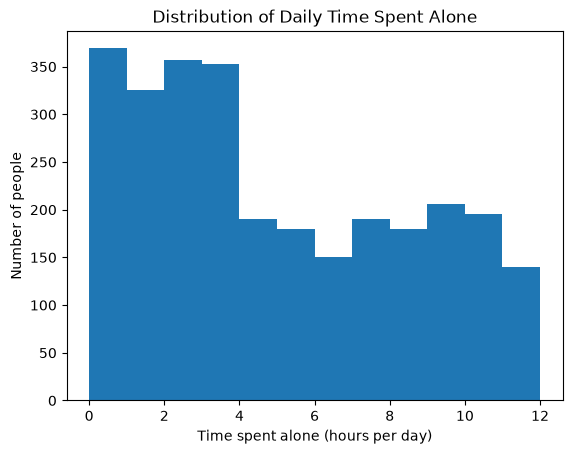

In [19]:
# Create and label your quantitative-feature visualization here.
time_alone = personality_df["Time_spent_Alone"].dropna()
time_alone.plot(kind="hist", bins=range(0, 13))
plt.title("Distribution of Daily Time Spent Alone")
plt.xlabel("Time spent alone (hours per day)")
plt.ylabel("Number of people")
plt.show()

**Which feature did you choose, and why is this chart appropriate?**

Your answer: I chose Time_spent_Alone, which records how many hours a person spends alone per day. It is a quantitative feature, so a histogram is appropriate because it shows the distribution across one-hour intervals. I excluded the 63 missing values for this feature, so the chart uses 2,837 records.

**In at least one complete sentence, describe what the figure tells you about this feature.** Refer to a visible pattern such as typical values, range, shape, or unusual observations, using values and units where possible. Describe the observations in your dataset without assuming they represent a larger population.

Your interpretation: In this dataset, daily time spent alone ranges from 0 to 11 hours. The highest bars are around 0–3 hours, then the counts drop noticeably around 4–6 hours and rise again around 7–10 hours before falling at 11. That dip and second cluster make the distribution look like it has multiple groups rather than one single peak.


### 4. Visualize one categorical feature

Choose a categorical feature and create an appropriate visualization of its distribution. A bar chart of category counts is a good choice; use `.value_counts()` to obtain numeric bar heights from text labels. Include a descriptive title and labels identifying the categories and counts or percentages on the axes. If you choose a pie chart for a small number of categories, label the slices and their shares instead of axes. Explain any excluded missing values or categories, and identify the denominator if you use percentages.


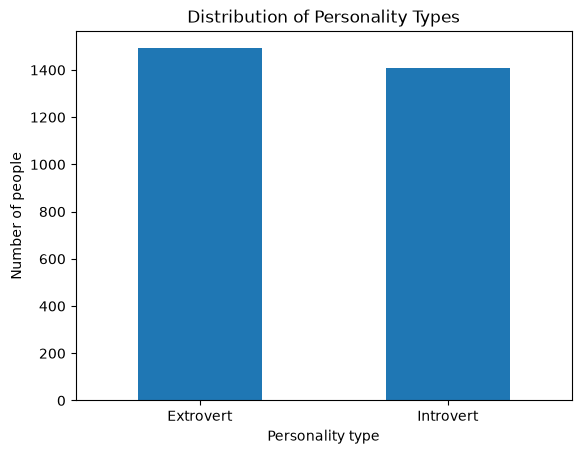

In [20]:
# Create and label your categorical-feature visualization here.
personality_counts = personality_df["Personality"].value_counts()
personality_counts
personality_counts.plot(kind="bar")
plt.title("Distribution of Personality Types")
plt.xlabel("Personality type")
plt.ylabel("Number of people")
plt.xticks(rotation=0)
plt.show()

**Which feature did you choose, and why is this chart appropriate?**

Your answer: I chose Personality, which is a categorical feature with two categories: Extrovert and Introvert. It has no missing values, so all 2,900 records are included. A bar chart is appropriate because it lets me compare the number of records in each category directly.

**In at least one complete sentence, describe what the figure tells you about this feature.** Identify a meaningful pattern, such as the most or least common category or a difference in counts or shares. Support the interpretation with evidence visible in your figure.

Your interpretation: In this dataset, Extrovert is slightly more common than Introvert: 1,491 records (51.4%) are Extrovert and 1,409 (48.6%) are Introvert. The difference is only 82 records, so the two categories are fairly balanced rather than one being clearly dominant.


## Reflect on AI assistance

Complete one of the following statements.

**If you used an AI tool:**

- Tool used:
- What I asked it to help with:
- One suggestion I checked against my code, chart, or output:
- What I accepted, modified, or rejected—and why:

**If you did not use an AI tool:**

- I did not use an AI tool for this assignment.
- One resource or troubleshooting strategy I used instead was:


Your response:
- Tool used: Opencode (Plan mode only)
- What I asked it to help with: I used it mainly as a tutor and editor—to explain Pandas and Matplotlib concepts, give feedback on my written answers, and review the completed file before submission to make sure I didn't miss anything. 
- One suggestion I checked against my code, chart, or output: It suggested using bins=range(0, 13) for the time-alone histogram. The axis looked like it went to 12, so I checked time_alone.max() and confirmed the largest observed value was 11.
- What I accepted, modified, or rejected—and why: I accepted the general approach for loading and plotting the data, but I typed and ran the code myself based off of the lecture notes. It found some typos on the final review which I then corrected. It tried to suggest a dataset to use but I searched for and chose my own. 

## Submission checklist

- All code cells run from top to bottom without errors.
- The destination-city bar chart has a descriptive title and labeled axes.
- The default, 5-bin, and 25-bin arrival-delay histograms are included and labeled.
- Both vertical-axis demonstrations are included.
- Every question has one response in its own answer cell.
- The sample questions are answered using the dataset documentation.
- The chosen dataset and its data dictionary are linked and described.
- The feature table includes a description, data type, storage type, and missing-value count for every feature.
- One quantitative and one categorical feature have appropriate labeled visualizations and at least one sentence of interpretation each.
- The chosen CSV is included in the `data` folder with the submitted notebook, and relative paths work.
- The AI-use reflection is complete and honest.
